In [1]:
%run 0_requirements.ipynb

In [2]:
# file = Path(r"/data/credit_risk_dataset.csv")
# df = pd.read_csv(file)
# df.head()

In [3]:
file_path = "credit_risk_dataset.csv"

df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "laotse/credit-risk-dataset",
  file_path
)

C:\Users\Marcus\AppData\Local\Temp\ipykernel_19912\3782789750.py:3: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


### Importacao de dados Kaggle (laotse/credit-risk-dataset)
https://www.kaggle.com/datasets/laotse/credit-risk-dataset

In [4]:
print(f"O dataset possui {df.shape[0]} linhas e {df.shape[1]} colunas")
print(f"\n>>>>> Valores nulos:")
print(f"{df.isnull().sum()}")
print(f"\n>>>>> Atributos e tipos de dados:")
print(f"{df.info()}")
print(f"\n>>>>> Estatistica basica dos dados:")
print(f"{df.describe()}")
df.head(10)

O dataset possui 32581 linhas e 12 colunas

>>>>> Valores nulos:
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

>>>>> Atributos e tipos de dados:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
5,21,9900,OWN,2.0,VENTURE,A,2500,7.14,1,0.25,N,2
6,26,77100,RENT,8.0,EDUCATION,B,35000,12.42,1,0.45,N,3
7,24,78956,RENT,5.0,MEDICAL,B,35000,11.11,1,0.44,N,4
8,24,83000,RENT,8.0,PERSONAL,A,35000,8.90,1,0.42,N,2
9,21,10000,OWN,6.0,VENTURE,D,1600,14.74,1,0.16,N,3


#### Conferencia de valores nulos e tipos de dados  
Existem valores nulos nos atributos _person_emp_length_ (prazo do emprestimo) e _loan_int_rate_ (taxa de juros)  

#### Conferencia de estatica basica do df  
Identificado que em _person_age_ existem outliers ou erros (idade maxima de 144 anos)  
Identificado que em _person_emp_length_ existem outliers ou erros (prazo maximo de 123 anos)  

In [5]:
#Resumo valores nulos person_emp_length
qtde_person_emp_na = df["person_emp_length"].isnull().sum()
qtde_person_emp_na_def = df[(df["person_emp_length"].isnull()) & (df["cb_person_default_on_file"] == "Y")].shape[0]
per_def_person_emp_na = qtde_person_emp_na_def/qtde_person_emp_na *100
print(f"Foram localizados {qtde_person_emp_na_def} casos de valores nulos na coluna person_emp_length, os quais estao inadimplentes, de um total de {qtde_person_emp_na} nulos ({per_def_person_emp_na:.2f}%)")

#Resumo valores nulos loan_int_rate
loan_int_rate_na = df["loan_int_rate"].isnull().sum()
loan_int_rate_na_def = df[(df["loan_int_rate"].isnull()) & (df["cb_person_default_on_file"] == "Y")].shape[0]
per_def_person_emp_na = loan_int_rate_na_def/loan_int_rate_na *100
print(f"Foram localizados {loan_int_rate_na_def} casos de valores nulos na coluna loan_int_rate, os quais estao inadimplentes, de um total de {loan_int_rate_na} nulos ({per_def_person_emp_na:.2f}%)")


Foram localizados 116 casos de valores nulos na coluna person_emp_length, os quais estao inadimplentes, de um total de 895 nulos (12.96%)
Foram localizados 532 casos de valores nulos na coluna loan_int_rate, os quais estao inadimplentes, de um total de 3116 nulos (17.07%)


In [6]:
#Ajusta valores nulos
#Tempo de emprego ajustado para zero (desemprego ou recem-emprego)
df["person_emp_length"] = (
    df["person_emp_length"]
    .fillna(
        df.groupby("loan_intent")["person_emp_length"].transform("median")
        )
 )

#Media de taxa ajustada para media considerando o rating da operacao e a intencao do uso
df["loan_int_rate"] = (
    df["loan_int_rate"]
    .fillna(
        df.groupby(["loan_grade", "loan_intent"])["loan_int_rate"].transform("median") 
        )
)

df.isnull().sum()

person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64

Ajuste dos valores nulos em _person_emp_length_ (prazo do emprestimo) e _loan_int_rate_ (taxa de juros)

In [7]:
#Avalia outliers person_age
df_age = df.sort_values(by="person_age", ascending=False)
print(df_age.head(10))

#Avalia outliers person_emp_length
df_length = df.sort_values(by="person_emp_length", ascending=False)
print(df_length.head(5))

#Remove outliers identificados
df = df[(df["person_age"] <= 100) & (df["person_emp_length"] <= 50)]

#Constacao da limpeza
df.describe()

       person_age  person_income person_home_ownership  person_emp_length  \
81            144         250000                  RENT                4.0   
183           144         200000              MORTGAGE                4.0   
32297         144        6000000              MORTGAGE               12.0   
575           123          80004                  RENT                2.0   
747           123          78000                  RENT                7.0   
32416          94          24000                  RENT                1.0   
32506          84          94800              MORTGAGE                2.0   
32422          80          64000                  RENT                7.0   
32355          78          48000                  RENT               41.0   
32534          76          75000                  RENT               23.0   

      loan_intent loan_grade  loan_amnt  loan_int_rate  loan_status  \
81        VENTURE          C       4800          13.57            0   
183     ED

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32574.000000,3.257400e+04,32574.000000,32574.000000,32574.000000,32574.000000,32574.000000,32574.000000
mean,27.718426,6.587848e+04,4.760576,9588.018051,11.013825,0.218180,0.170202,5.804108
std,6.204987,5.253194e+04,3.981181,6320.249598,3.212462,0.413017,0.106755,4.053873
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.880000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.480000,0.000000,0.230000,8.000000
max,94.000000,2.039784e+06,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


Exibicao dos outliers para melhor entendimento.

In [8]:
#Remove outliers identificados
df = df[(df["person_age"] <= 100) & (df["person_emp_length"] <= 50)]

#Constacao da limpeza
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32574.000000,3.257400e+04,32574.000000,32574.000000,32574.000000,32574.000000,32574.000000,32574.000000
mean,27.718426,6.587848e+04,4.760576,9588.018051,11.013825,0.218180,0.170202,5.804108
std,6.204987,5.253194e+04,3.981181,6320.249598,3.212462,0.413017,0.106755,4.053873
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.880000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.480000,0.000000,0.230000,8.000000
max,94.000000,2.039784e+06,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


Remoção dos outliers realizada.

In [9]:
%run 0_functions.ipynb


Para maior limpeza no codigo criei uma funcao para formatação e plotagem dos gráficos (`bar_plot`)
* Atributos
    * `col_alvo`: objetivo de analise no eixo y;
    * `d1`: Dados para analise no eixo x primário;
    * `viz_d1`: Cálculo dos dados no eixo x primário "qtd" (quantidade), "volume" (soma), "media" (média), "media_pond" (média ponderada);
    * `d2`: Dados para analise no eixo x secundário;
    * `viz_d2`: Cálculo dos dados no eixo x secundário "qtd" (quantidade), "volume" (soma), "media" (média), "media_pond" (média ponderada).

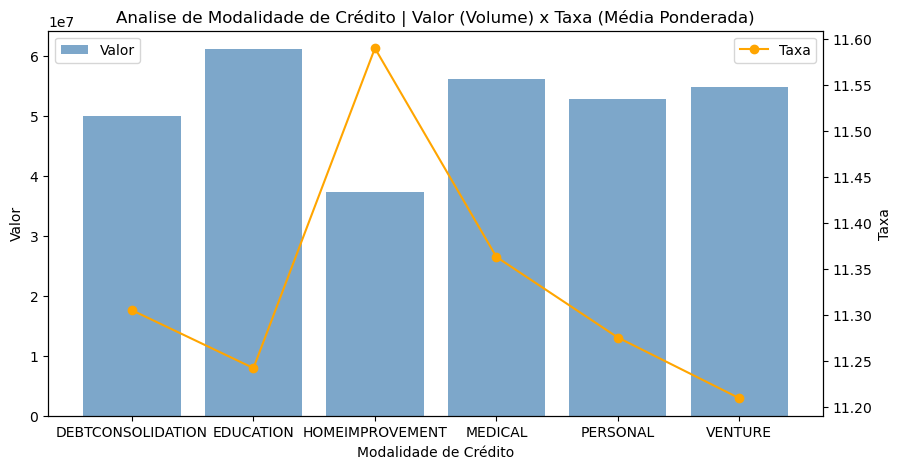

                     Volume  Média Ponderada  Qtd Inadimplente  \
loan_intent                                                      
DEBTCONSOLIDATION  50008550        11.305140              1490   
EDUCATION          61165325        11.242267              1111   
HOMEIMPROVEMENT    37349675        11.589710               941   
MEDICAL            56214925        11.363029              1621   
PERSONAL           52816800        11.275509              1097   
VENTURE            54764825        11.209570               847   

                   Volume Inadimplente  
loan_intent                             
DEBTCONSOLIDATION             16561650  
EDUCATION                     12156450  
HOMEIMPROVEMENT                9305875  
MEDICAL                       18146000  
PERSONAL                      11507800  
VENTURE                        9412600  


(<Figure size 1000x500 with 2 Axes>, None)

In [10]:
#Avaliacao dados da base (relacao quantidade x taxa media)
bar_plot(
    col_alvo="loan_intent",
    d1="loan_amnt",
    viz_d1="volume",
    d2="loan_int_rate",
    viz_d2="media_pond")

As modalidades com maior precificação são: 
* HOMEIMPROVEMENT (volume: 3,7 mi - taxa média de: 11,59%) e 
* MEDICAL (volume: 5,6 mi - taxa média de: 11,36%).

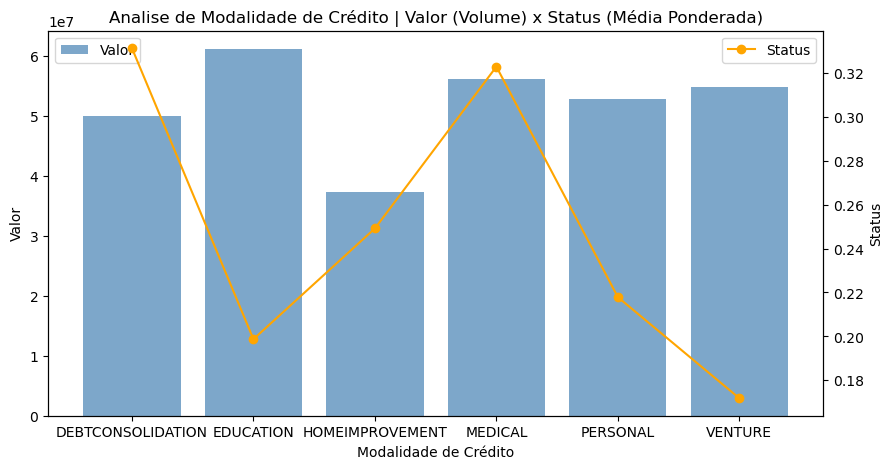

                     Volume  Média Ponderada  Qtd Inadimplente  \
loan_intent                                                      
DEBTCONSOLIDATION  50008550         0.331176              1490   
EDUCATION          61165325         0.198747              1111   
HOMEIMPROVEMENT    37349675         0.249155               941   
MEDICAL            56214925         0.322797              1621   
PERSONAL           52816800         0.217881              1097   
VENTURE            54764825         0.171873               847   

                   Volume Inadimplente  
loan_intent                             
DEBTCONSOLIDATION             16561650  
EDUCATION                     12156450  
HOMEIMPROVEMENT                9305875  
MEDICAL                       18146000  
PERSONAL                      11507800  
VENTURE                        9412600  


(<Figure size 1000x500 with 2 Axes>, None)

In [11]:
#Avaliacao dados da base (relacao volume de operacoes x inadimplencia)
bar_plot(
    col_alvo="loan_intent",
    d1="loan_amnt",
    viz_d1="volume",
    d2="loan_status",
    viz_d2="media_pond")

As modalidades com maior inadimplencia são: 
* DEBTCONSOLIDATION  (1.490 operações - volume inadimplente: 1,65 mi - 33,1%), 
* MEDICAL (1.621 operações - volume inadimplente: 1,81 mi - 32,3%) e 
* HOMEIMPROVEMENT: (941 operações - 0,93 mi - 24,9%).

As modalidades com menor inadimplência são:
* VENTURE (847 operações - volume inadimplente: 0,94 mi - 17,2%) e
* EDUCATION (1.111 operações - volume inadimplente: 1,22 mi - 19,9%).


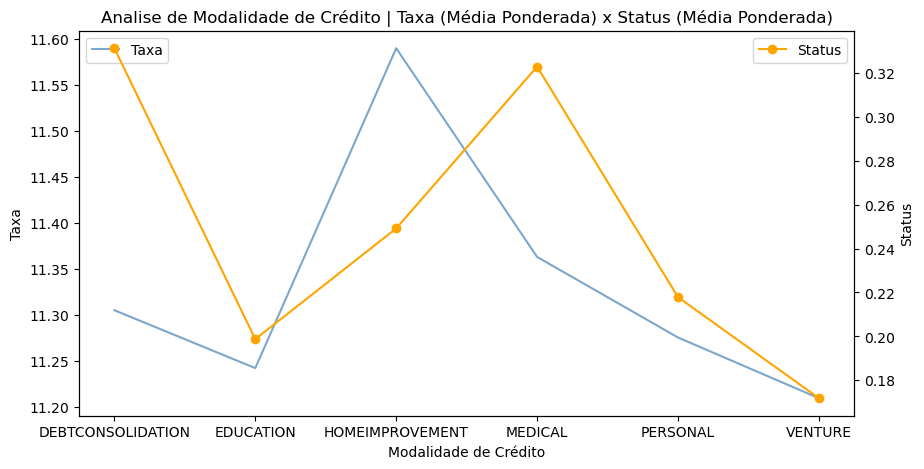

                   Média Ponderada  Média Ponderada  Qtd Inadimplente  \
loan_intent                                                             
DEBTCONSOLIDATION        11.305140         0.331176              1490   
EDUCATION                11.242267         0.198747              1111   
HOMEIMPROVEMENT          11.589710         0.249155               941   
MEDICAL                  11.363029         0.322797              1621   
PERSONAL                 11.275509         0.217881              1097   
VENTURE                  11.209570         0.171873               847   

                   Volume Inadimplente  
loan_intent                             
DEBTCONSOLIDATION             16561650  
EDUCATION                     12156450  
HOMEIMPROVEMENT                9305875  
MEDICAL                       18146000  
PERSONAL                      11507800  
VENTURE                        9412600  


(<Figure size 1000x500 with 2 Axes>, None)

In [12]:
#Avaliacao dados da base (relacao volume de operacoes x inadimplencia)
line_plot(
    col_alvo="loan_intent",
    d1="loan_int_rate",
    viz_d1="media_pond",
    d2="loan_status",
    viz_d2="media_pond")

Em análise à relação entre a precificação e inadimplência vemos maior distorção negativa entre as modalidades:
* DEBTCONSOLIDATION (taxa média: 11,3% - inadimplência: 33,1%) e 
* MEDICAL (taxa média: 11,4% - inadimplência: 32,3%)


In [13]:
df_rep_g = pd.DataFrame(
    df.groupby("loan_grade")["loan_amnt"]
    .sum()
    .apply(lambda x: x / df["loan_amnt"].sum())
    .sort_index()
    .rename("Volume")
) * 100

print(df_rep_g)


               Volume
loan_grade           
A           29.459439
B           33.432494
C           19.048830
D           12.584637
E            3.986575
F            1.135654
G            0.352371


Aproximadamente 63% de toda carteira enquadra-se nos riscos A e B.

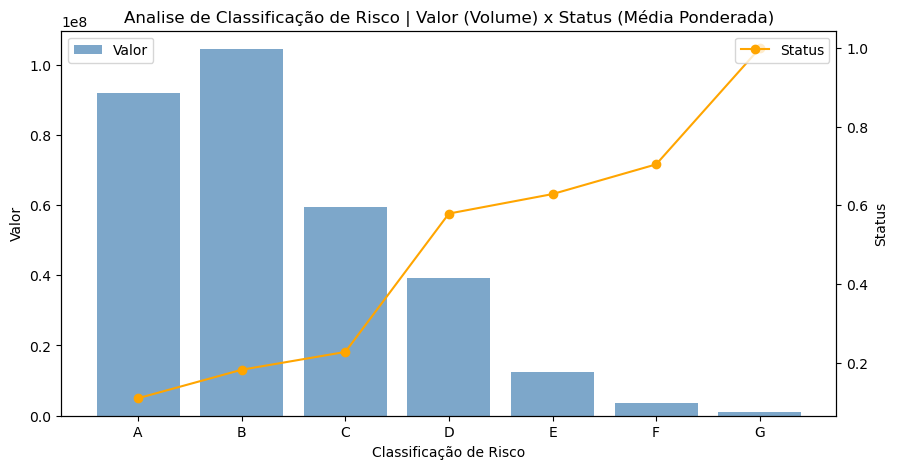

               Volume  Média Ponderada  Qtd Inadimplente  Volume Inadimplente
loan_grade                                                                   
A            92007750         0.110888              1073             10202525
B           104416400         0.183117              1701             19120425
C            59493325         0.228254              1339             13579600
D            39304350         0.579201              2140             22765100
E            12450875         0.628624               621              7826925
F             3546875         0.703965               170              2496875
G             1100525         0.998546                63              1098925


(<Figure size 1000x500 with 2 Axes>, None)

In [14]:
#Avaliacao dados da base (relacao quantidade de operacoes x rating da operacao - visao inadimplencia)
bar_plot(
    col_alvo="loan_grade",
    d1="loan_amnt",
    viz_d1="volume",
    d2="loan_status",
    viz_d2="media_pond")

É possível evidenciar que a inadimplência gera um spike relevante a partir do rating D+ (o que é natural), indicando que boa parte das operações estão classificadas em D+= por conta da inadimplência.
* D: 57,9% da carteira está inadimplente,
* E: 62,9% da carteira está inadimplente,
* F: 70,4% da carteira está inadimplente,
* G: 99,9% da carteira está inadimplente.

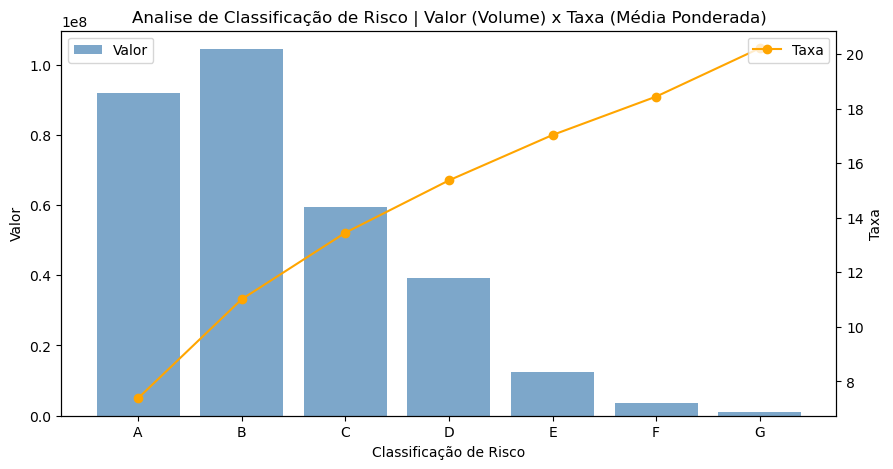

               Volume  Média Ponderada  Qtd Inadimplente  Volume Inadimplente
loan_grade                                                                   
A            92007750         7.385747              1073             10202525
B           104416400        11.014692              1701             19120425
C            59493325        13.453496              1339             13579600
D            39304350        15.372646              2140             22765100
E            12450875        17.036790               621              7826925
F             3546875        18.444745               170              2496875
G             1100525        20.218572                63              1098925


(<Figure size 1000x500 with 2 Axes>, None)

In [15]:
#Avaliacao dados da base (relacao quantidade de operacoes x rating da operacao - visao de taxa media)
bar_plot(
    col_alvo="loan_grade",
    d1="loan_amnt",
    viz_d1="volume",
    d2="loan_int_rate",
    viz_d2="media_pond")


É possível evidenciar que a taxa média acompanha o risco de crédito, indicando que no momento da concessão o risco de crédito foi precificado:
* D: 59,0% da carteira está inadimplente (taxa média de 15,4%),
* E: 64,4% da carteira está inadimplente (taxa média de 17,0%),
* F: 70,5% da carteira está inadimplente (taxa média de 18,5%),
* G: 98,4% da carteira está inadimplente (taxa média de 20,2%).

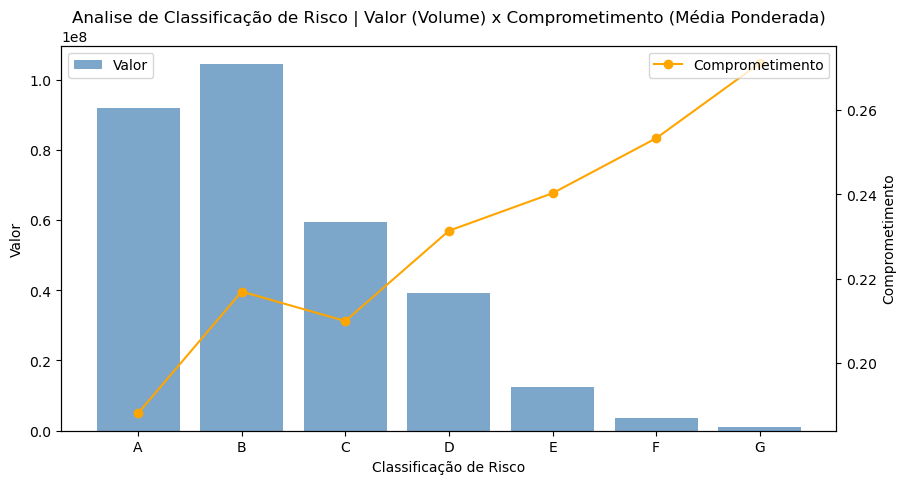

               Volume  Média Ponderada  Qtd Inadimplente  Volume Inadimplente
loan_grade                                                                   
A            92007750         0.188148              1073             10202525
B           104416400         0.216957              1701             19120425
C            59493325         0.209972              1339             13579600
D            39304350         0.231354              2140             22765100
E            12450875         0.240239               621              7826925
F             3546875         0.253253               170              2496875
G             1100525         0.271024                63              1098925


(<Figure size 1000x500 with 2 Axes>, None)

In [16]:
#Avaliacao dados da base (relacao do rating da operacao na visão volume operacoes x comprometimento de renda)
bar_plot(
    col_alvo="loan_grade",
    d1="loan_amnt",
    viz_d1="volume",
    d2="loan_percent_income",
    viz_d2="media_pond")

In [17]:
df_rep_g

,Volume
loan_grade,
A,29.459439
B,33.432494
C,19.048830
D,12.584637
E,3.986575
F,1.135654
G,0.352371


As classes D+ apresentam o maior comprometimento dos rendimentos
* D: 23,1%
* E: 24,0%
* F: 25,3%
* G: 27,1%

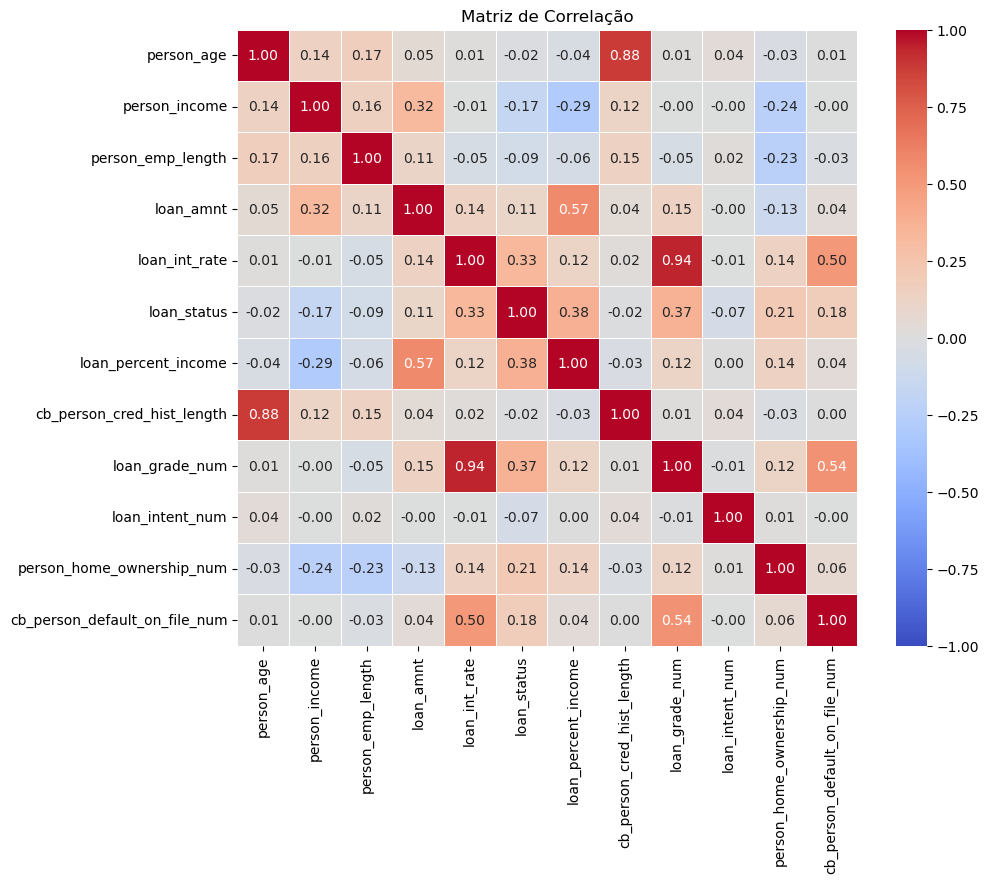

loan_percent_income              0.379250
loan_grade_num                   0.373042
loan_int_rate                    0.333639
person_home_ownership_num        0.211576
cb_person_default_on_file_num    0.179002
person_income                   -0.168485
loan_amnt                        0.105240
person_emp_length               -0.085613
loan_intent_num                 -0.065584
person_age                      -0.020687
cb_person_cred_hist_length      -0.015472
Name: loan_status, dtype: float64


In [18]:
df_n = df.copy()

for col in ["loan_grade", "loan_intent", "person_home_ownership", "cb_person_default_on_file"]:
    df_n[f"{col}_num"] = df_n[col].astype("category").cat.codes

df_n = df_n.drop(columns=["loan_grade", "loan_intent", "person_home_ownership", "cb_person_default_on_file"])

df_numerico = df_n.select_dtypes(include="number")
corr = df_numerico.corr()

corr_status = (
    corr["loan_status"]
    .drop("loan_status")
    .sort_values(key=abs, ascending=False)
)

# visualização
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5
)
plt.title("Matriz de Correlação")
plt.show()

print(corr_status)

Em análise à matriz de correlação dos dados, especificamente em relação ao status de inadimplência (loan_status == 1), percebemos que alguns atributos se destacam nessa visão:
* `loan_percent_income` (comprometimento da renda)
* `person_home_ownership_num` (tipo de moradia)
* `cb_person_default_on_file_num` (restritivos)

Outro ponto que reforça a suspeita de que a precificação considerou o risco de crédito no momento da concessão (ou taxas pós-fixadas) está no fato de que a taxa de juros (_loan_int_rate_) apresenta correlação positiva com a inadimplência.